In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#LOAD DATASET

In [4]:
df=pd.read_excel('/content/Netflix.xlsx')

#BASIC INSPECTION OF DATA SET

In [5]:
df.shape

(102000, 29)

In [7]:
df.head()

,Transaction_ID,Transaction_Date,Customer_ID,Customer_Name,Age,Gender,Country,Subscription_Plan,Payment_Method,Device_Type,...,Churn_Flag,City,Region,Monthly_Price,Gross_Revenue,Discount_Amount,Revenue,Cost,Profit,Renewal_Flag
0,NTX1092272,2023-11-17,CUST124819,Customer_16589,55.0,Female,USA,Basic,Credit Card,Smart TV,...,No,Toronto,North America,7.99,7.99,0.000,7.990,3.790596,4.199404,Yes
1,NTX1011772,2024-11-15,CUST104373,Customer_4869,54.0,Female,Brazil,Basic,UPI,Smart TV,...,No,Sydney,South America,7.99,15.98,0.000,15.980,8.731865,7.248135,Yes
2,NTX1086373,2023-12-21,CUST101981,Customer_22075,51.0,Female,Mexico,Standard,PayPal,Tablet,...,No,Tokyo,North America,12.99,12.99,0.000,12.990,7.682273,5.307727,Yes
3,NTX1094007,2023-06-29,CUST112843,Customer_15134,37.0,Male,India,Basic,Net Banking,Tablet,...,No,Toronto,Asia,7.99,7.99,0.799,7.191,2.704733,4.486267,Yes
4,NTX1051137,2025-03-13,CUST101309,Customer_12978,55.0,Male,Australia,Standard,Debit Card,Mobile,...,No,Berlin,Oceania,12.99,25.98,0.000,25.980,12.314695,13.665305,No


In [6]:
df.tail()

,Transaction_ID,Transaction_Date,Customer_ID,Customer_Name,Age,Gender,Country,Subscription_Plan,Payment_Method,Device_Type,...,Churn_Flag,City,Region,Monthly_Price,Gross_Revenue,Discount_Amount,Revenue,Cost,Profit,Renewal_Flag
101995,NTX1051277,2023-11-27,CUST106541,Customer_11290,24.0,Other,Mexico,Standard,Credit Card,Laptop,...,No,Hyderabad,North America,12.99,12.99,0.0,12.99,5.058675,7.931325,No
101996,NTX1029624,2023-10-10,CUST121926,Customer_3273,49.0,Male,India,Standard,UPI,Laptop,...,No,Toronto,Asia,12.99,12.99,0.0,12.99,5.829387,7.160613,Yes
101997,NTX1074522,2025-11-20,CUST108278,Customer_14178,59.0,Other,Japan,Basic,UPI,Tablet,...,No,Tokyo,Asia,7.99,7.99,0.0,7.99,4.104814,3.885186,Yes
101998,NTX1032134,2025-03-01,CUST114133,Customer_19162,33.0,Other,Japan,Basic,UPI,Laptop,...,No,New York,Asia,7.99,7.99,0.0,7.99,3.086972,4.903028,No
101999,NTX1067841,2025-06-17,CUST118341,Customer_22978,57.0,Other,France,Basic,Debit Card,Laptop,...,No,Toronto,Europe,7.99,7.99,0.0,7.99,3.290212,4.699788,No


In [9]:
df.columns

Index(['Transaction_ID', 'Transaction_Date', 'Customer_ID', 'Customer_Name',
       'Age', 'Gender', 'Country', 'Subscription_Plan', 'Payment_Method',
       'Device_Type', 'Content_Type', 'Genre', 'Subscription_Status',
       'Quantity', 'Discount_Percent', 'Viewing_Hours', 'Rating',
       'Customer_Tenure_Months', 'Support_Tickets', 'Churn_Flag', 'City',
       'Region', 'Monthly_Price', 'Gross_Revenue', 'Discount_Amount',
       'Revenue', 'Cost', 'Profit', 'Renewal_Flag'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102000 entries, 0 to 101999
Data columns (total 29 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   Transaction_ID          102000 non-null  object        
 1   Transaction_Date        102000 non-null  datetime64[ns]
 2   Customer_ID             102000 non-null  object        
 3   Customer_Name           100470 non-null  object        
 4   Age                     101796 non-null  float64       
 5   Gender                  101181 non-null  object        
 6   Country                 100988 non-null  object        
 7   Subscription_Plan       102000 non-null  object        
 8   Payment_Method          100789 non-null  object        
 9   Device_Type             102000 non-null  object        
 10  Content_Type            102000 non-null  object        
 11  Genre                   102000 non-null  object        
 12  Subscription_Status     102000

In [10]:
df.describe()

,Transaction_Date,Age,Quantity,Discount_Percent,Customer_Tenure_Months,Support_Tickets,Monthly_Price,Gross_Revenue,Discount_Amount,Revenue,Cost,Profit
count,102000,101796.000000,102000.000000,102000.000000,102000.00000,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000
mean,2024-07-28 20:07:31.482353408,41.496287,1.200216,0.045641,24.47000,0.697569,12.238088,14.682076,0.648467,14.033609,7.031654,7.001955
min,2023-01-01 00:00:00,5.000000,1.000000,0.000000,1.00000,0.000000,7.990000,7.990000,0.000000,6.392000,2.237718,2.240292
25%,2023-10-02 00:00:00,30.000000,1.000000,0.000000,12.00000,0.000000,7.990000,7.990000,0.000000,7.990000,4.560308,4.561237
50%,2024-07-02 00:00:00,41.000000,1.000000,0.000000,25.00000,1.000000,12.990000,12.990000,0.000000,12.990000,6.334383,6.312397
75%,2025-04-03 00:00:00,53.000000,1.000000,0.100000,36.00000,1.000000,12.990000,17.990000,1.198500,16.191000,8.294327,8.254665
max,2099-12-31 00:00:00,150.000000,2.000000,1.500000,48.00000,6.000000,17.990000,35.980000,7.196000,35.980000,23.386023,23.374735
std,NaN,14.024076,0.400164,0.074607,13.85562,0.836175,3.624292,6.689226,0.987245,6.466178,3.516218,3.483585


In [11]:
df.dtypes

,0
Transaction_ID,object
Transaction_Date,datetime64[ns]
Customer_ID,object
Customer_Name,object
Age,float64
Gender,object
Country,object
Subscription_Plan,object
Payment_Method,object
Device_Type,object


#CHECK AND REMOVE DUPLICATES

In [12]:
df.duplicated().sum()

np.int64(2000)

In [13]:
df.drop_duplicates(inplace=True)

#DROPPING THE COLUMNS WHICH HAVE MORE THAN 50% NULL VALUES

In [14]:
df.isnull().sum()

,0
Transaction_ID,0
Transaction_Date,0
Customer_ID,0
Customer_Name,1498
Age,200
Gender,800
Country,996
Subscription_Plan,0
Payment_Method,1197
Device_Type,0


In [15]:
threshold=len(df)*0.5

In [16]:
df=df.dropna(thresh=threshold,axis=1)

In [17]:
df.columns

Index(['Transaction_ID', 'Transaction_Date', 'Customer_ID', 'Customer_Name',
       'Age', 'Gender', 'Country', 'Subscription_Plan', 'Payment_Method',
       'Device_Type', 'Content_Type', 'Genre', 'Subscription_Status',
       'Quantity', 'Discount_Percent', 'Viewing_Hours', 'Rating',
       'Customer_Tenure_Months', 'Support_Tickets', 'Churn_Flag', 'City',
       'Region', 'Monthly_Price', 'Gross_Revenue', 'Discount_Amount',
       'Revenue', 'Cost', 'Profit', 'Renewal_Flag'],
      dtype='object')

#FORMATTING THE COLUMNS

In [18]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [19]:
df.columns

Index(['transaction_id', 'transaction_date', 'customer_id', 'customer_name',
       'age', 'gender', 'country', 'subscription_plan', 'payment_method',
       'device_type', 'content_type', 'genre', 'subscription_status',
       'quantity', 'discount_percent', 'viewing_hours', 'rating',
       'customer_tenure_months', 'support_tickets', 'churn_flag', 'city',
       'region', 'monthly_price', 'gross_revenue', 'discount_amount',
       'revenue', 'cost', 'profit', 'renewal_flag'],
      dtype='object')

In [20]:
df["transaction_id"].unique()

array(['NTX1092272', 'NTX1011772', 'NTX1086373', ..., 'NTX1074522',
       'NTX1032134', 'NTX1067841'], dtype=object)

In [21]:
df["transaction_date"].unique()

<DatetimeArray>
['2023-11-17 00:00:00', '2024-11-15 00:00:00', '2023-12-21 00:00:00',
 '2023-06-29 00:00:00', '2025-03-13 00:00:00', '2025-07-02 00:00:00',
 '2025-05-21 00:00:00', '2024-10-23 00:00:00', '2024-07-09 00:00:00',
 '2023-07-20 00:00:00',
 ...
 '2024-12-10 00:00:00', '2025-04-26 00:00:00', '2023-02-01 00:00:00',
 '2024-10-07 00:00:00', '2023-03-26 00:00:00', '2024-03-12 00:00:00',
 '2025-03-10 00:00:00', '2024-11-28 00:00:00', '2025-04-11 00:00:00',
 '2024-12-18 00:00:00']
Length: 1097, dtype: datetime64[ns]

In [22]:
df["customer_id"].unique()

array(['CUST124819', 'CUST104373', 'CUST101981', ..., 'CUST106450',
       'CUST122931', 'CUST121820'], dtype=object)

In [23]:
df["viewing_hours"].unique()

array([25, 16, 39.4, 36.2, 27.4, 8.9, 4, 11.6, 22.5, 32.8, 24.2, 17.2,
       45.2, 28, 2.9, 5, 30.8, 45, 14.9, 9.2, 26.6, 50.7, 56.5, 12.5,
       27.5, 21.1, 41, 28.3, 13.3, 46, 33.6, 21.8, 20.1, 21.6, 90.1, 8.8,
       4.4, 15.6, 48.6, 36.1, 23.6, 19.4, 38.8, 16.6, 14.3, 11.5, 17.4,
       14.1, 23.7, 14.6, 35.4, 18, 12.6, 47.1, 23, 15.9, 25.6, 42.7, 9.6,
       6.8, 15.7, 36, 17.8, 5.8, 22.2, 16.1, 20.8, 54.1, 28.7, 29.3, 37,
       26, 25.1, 11, 8.7, 50.5, 26.8, 31.9, 38.3, 36.8, 28.6, 2.8, 32.3,
       15.5, 10.5, 38.4, 10.7, 11.9, 13.5, 35.7, 8.3, 21.4, 9, 13.1, 7.1,
       20.2, 24.1, 56.6, 6.5, 16.3, 37.8, 16.2, 44.6, 3, 12.3, 39.2, 31.2,
       3.1, 31, 19.8, 38.1, 41.5, 18.5, 22.8, 26.4, 6, 38.6, 51.9, 44.4,
       64.3, 24.3, 29, 15.3, 9.7, 35.2, 9.8, 56.4, 33.4, 21.5, 43.3, 94.6,
       23.8, 11.7, 20.4, 34.8, 8.6, 39.1, 37.9, 29.8, 4.7, 18.6, 8.1,
       37.2, 38, 17.6, 19.1, 34.3, 24.6, 16.8, 15.4, 29.2, 8.2, 13.9,
       27.9, 36.4, 24, 34.2, 20.3, 14.4, 18.8, 44.8, 38.

In [24]:
df["genre"].unique()

array(['Documentary', 'Drama', 'Comedy', 'Romance', 'Animation', 'Action',
       'Thriller', 'Sci-Fi', 'ERROR'], dtype=object)

In [26]:
df["rating"].unique()

array([nan, 5, 4, 2, 3, 1, 'Unknown'], dtype=object)

In [25]:
df["gross_revenue"].unique()

array([ 7.99, 15.98, 12.99, 25.98, 17.99, 35.98])

#DEALING WITH NULL VALUES

In [27]:
df.isnull().sum()

,0
transaction_id,0
transaction_date,0
customer_id,0
customer_name,1498
age,200
gender,800
country,996
subscription_plan,0
payment_method,1197
device_type,0


In [28]:
num_col=df.select_dtypes(include='number').columns

In [29]:
num_col

Index(['age', 'quantity', 'discount_percent', 'customer_tenure_months',
       'support_tickets', 'monthly_price', 'gross_revenue', 'discount_amount',
       'revenue', 'cost', 'profit'],
      dtype='object')

In [30]:
cat_col=df.select_dtypes(include='object').columns

In [31]:
cat_col

Index(['transaction_id', 'customer_id', 'customer_name', 'gender', 'country',
       'subscription_plan', 'payment_method', 'device_type', 'content_type',
       'genre', 'subscription_status', 'viewing_hours', 'rating', 'churn_flag',
       'city', 'region', 'renewal_flag'],
      dtype='object')

In [32]:
df.dtypes

,0
transaction_id,object
transaction_date,datetime64[ns]
customer_id,object
customer_name,object
age,float64
gender,object
country,object
subscription_plan,object
payment_method,object
device_type,object


In [33]:
df.columns

Index(['transaction_id', 'transaction_date', 'customer_id', 'customer_name',
       'age', 'gender', 'country', 'subscription_plan', 'payment_method',
       'device_type', 'content_type', 'genre', 'subscription_status',
       'quantity', 'discount_percent', 'viewing_hours', 'rating',
       'customer_tenure_months', 'support_tickets', 'churn_flag', 'city',
       'region', 'monthly_price', 'gross_revenue', 'discount_amount',
       'revenue', 'cost', 'profit', 'renewal_flag'],
      dtype='object')

#Replace Error Values

In [34]:
for col in cat_col:
    print(col, df[col].astype(str).str.contains("UNKNOWN|ERROR").sum())

transaction_id 0
customer_id 0
customer_name 300
gender 0
country 0
subscription_plan 0
payment_method 0
device_type 0
content_type 0
genre 300
subscription_status 0
viewing_hours 200
rating 0
churn_flag 0
city 0
region 0
renewal_flag 0


In [35]:
df.replace(["UNKNOWN", "ERROR", "unknown", "error"], np.nan, inplace=True)

/tmp/ipykernel_1997/726532526.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace(["UNKNOWN", "ERROR", "unknown", "error"], np.nan, inplace=True)


In [36]:
df.dtypes

,0
transaction_id,object
transaction_date,datetime64[ns]
customer_id,object
customer_name,object
age,float64
gender,object
country,object
subscription_plan,object
payment_method,object
device_type,object


#FILLING NUMERICAL COLUMNS WITH MEDIAN

In [37]:
df.isnull().sum()

,0
transaction_id,0
transaction_date,0
customer_id,0
customer_name,1798
age,200
gender,800
country,996
subscription_plan,0
payment_method,1197
device_type,0


In [38]:
df["viewing_hours"] = pd.to_numeric(df["viewing_hours"], errors="coerce")

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

In [39]:
num_col = df.select_dtypes(include="number").columns

In [40]:
num_col

Index(['age', 'quantity', 'discount_percent', 'viewing_hours', 'rating',
       'customer_tenure_months', 'support_tickets', 'monthly_price',
       'gross_revenue', 'discount_amount', 'revenue', 'cost', 'profit'],
      dtype='object')

In [41]:
for col in num_col:
 df[col] = df[col].fillna(df[col].median())

In [42]:
cat_col = df.select_dtypes(include="object").columns

In [43]:
cat_col

Index(['transaction_id', 'customer_id', 'customer_name', 'gender', 'country',
       'subscription_plan', 'payment_method', 'device_type', 'content_type',
       'genre', 'subscription_status', 'churn_flag', 'city', 'region',
       'renewal_flag'],
      dtype='object')

#FILLING CATEGORICAL COLUMNS WITH MODE

In [44]:
df[col]=df[col].fillna(df[col].mode()[0])

In [45]:
df[(df["age"] < 18) | (df["age"] > 100)].shape

(100, 29)

In [46]:
df = df[(df["age"] >= 18) & (df["age"] <= 100)]

#OUTLIERS

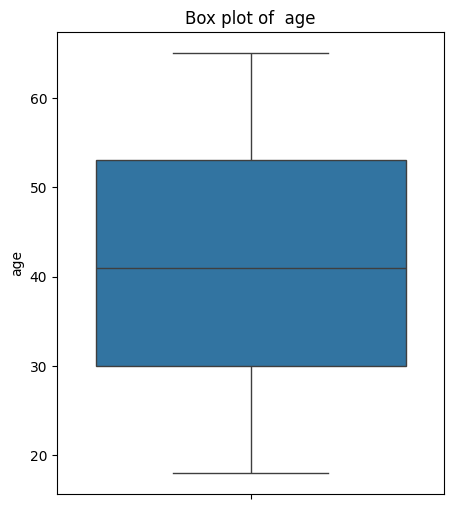

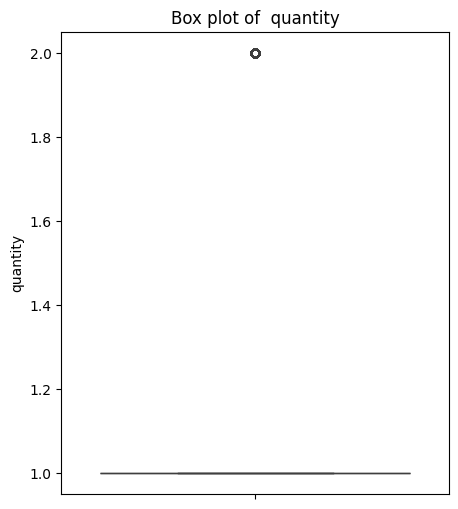

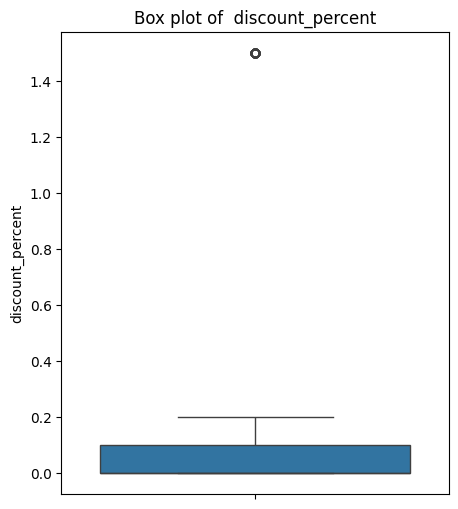

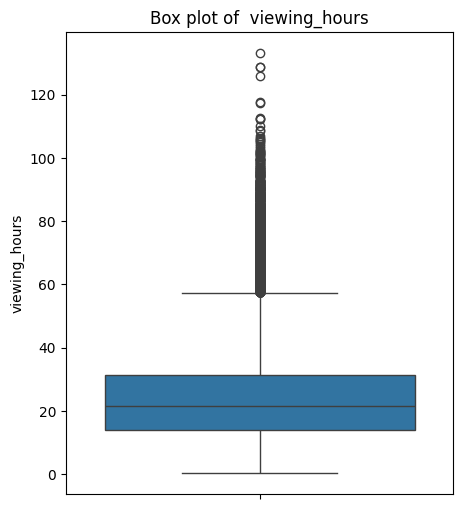

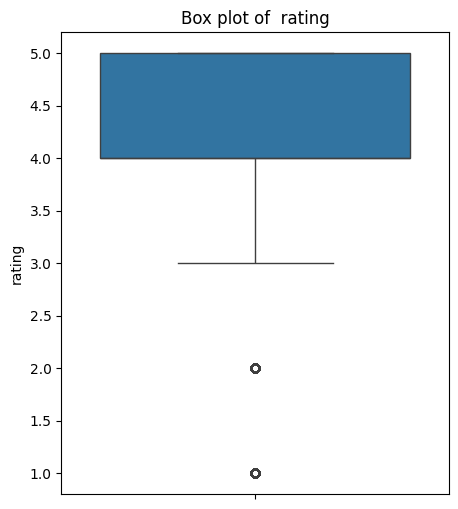

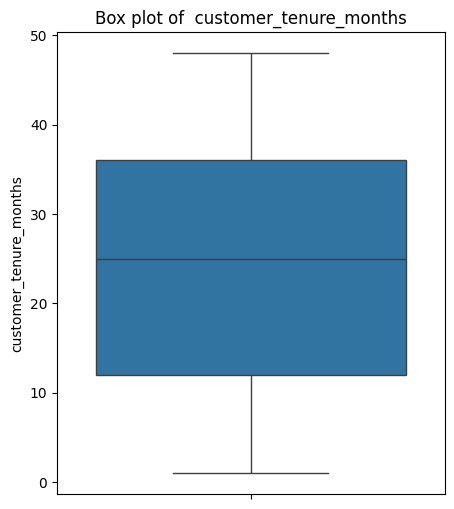

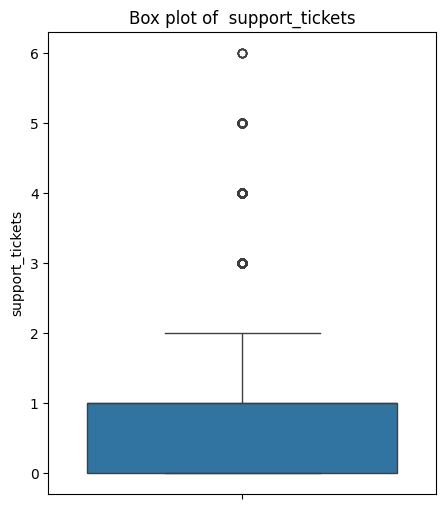

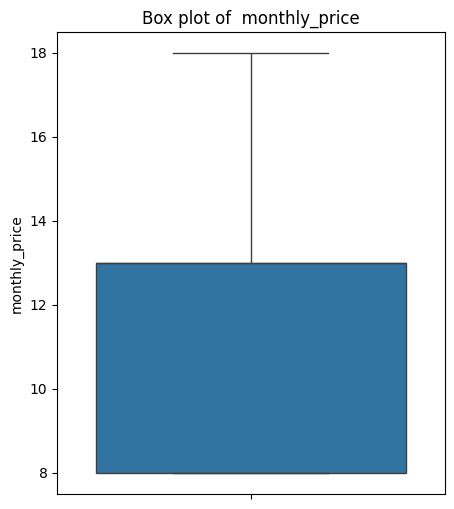

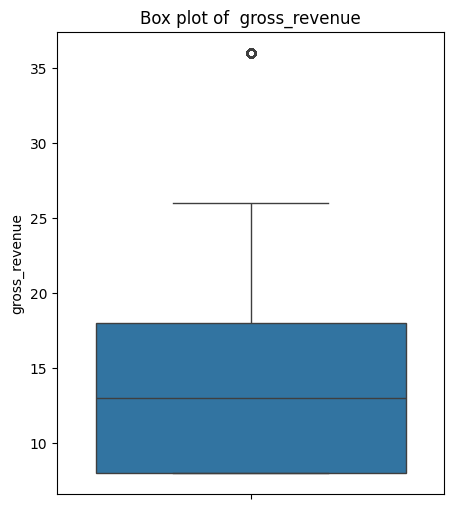

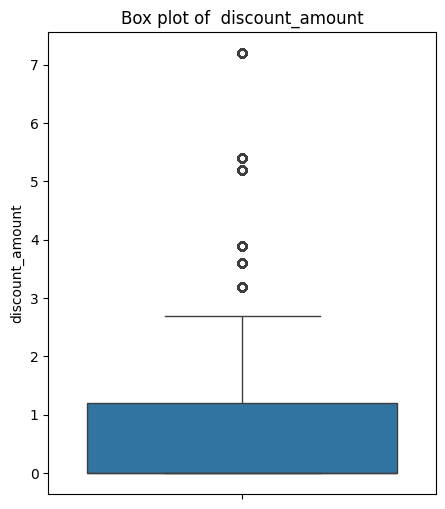

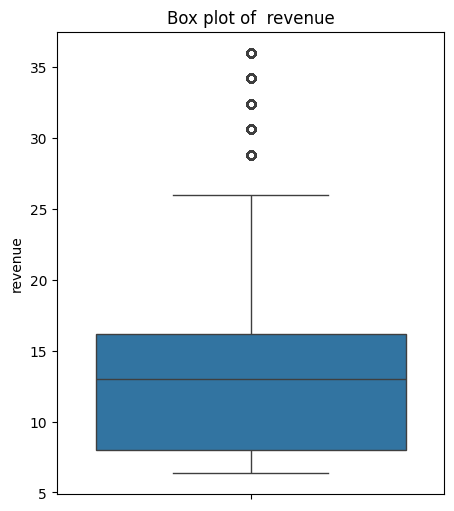

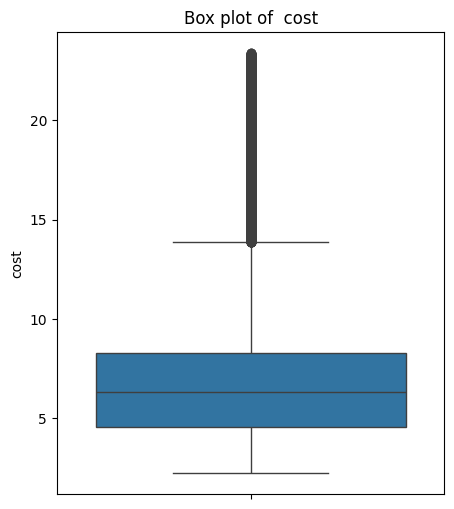

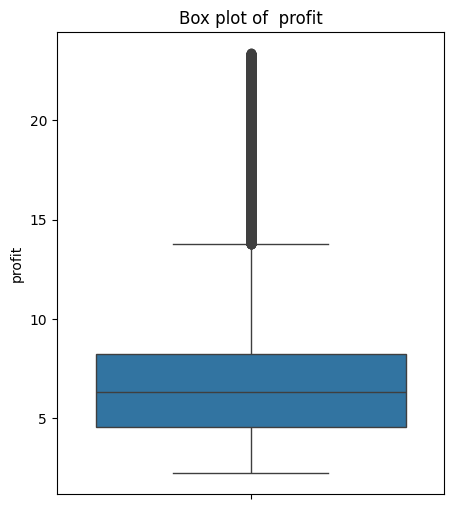

In [47]:
for col in num_col :
  plt.figure(figsize = (5,6))
  sns.boxplot(data = df , y = df[col])
  plt.title(f"Box plot of  {col}")

#EDA

In [64]:
# 1. Which Subscription Plan Has the Highest Number of Customers

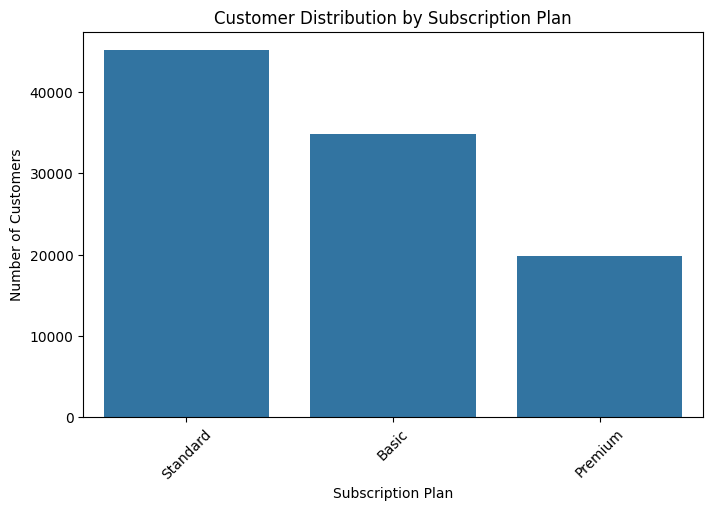

In [65]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="subscription_plan",
    order=df["subscription_plan"].value_counts().index
)

plt.title("Customer Distribution by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

In [ ]:
#Which Country Generates the Highest Revenue

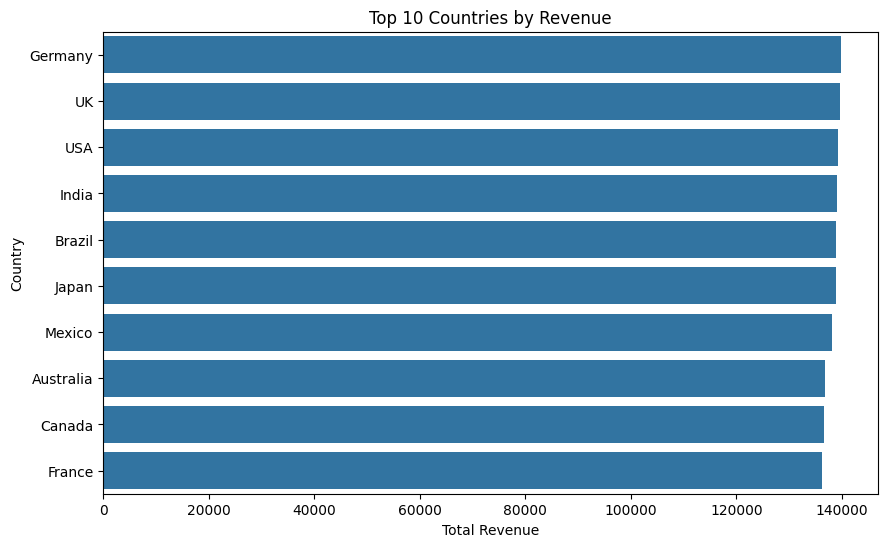

In [66]:
country_revenue = (
    df.groupby("country")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=country_revenue.values,
    y=country_revenue.index
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

plt.show()

In [ ]:
# Which Subscription Plan Has the Highest Churn Rate


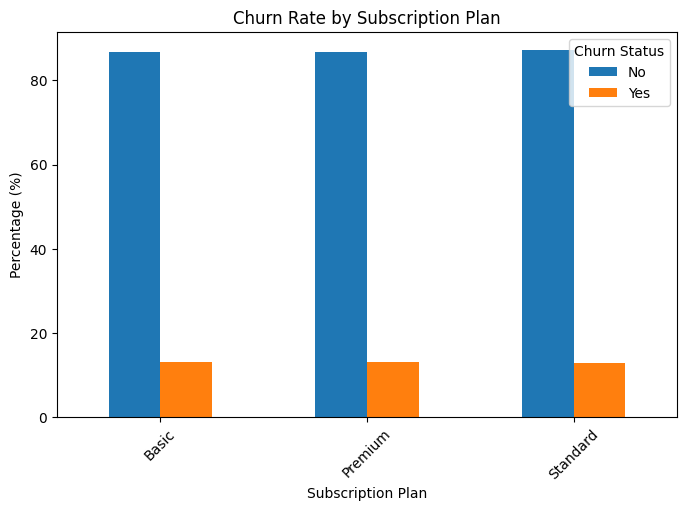

In [67]:
churn_rate_plan = (
    pd.crosstab(
        df["subscription_plan"],
        df["churn_flag"],
        normalize="index"
    ) * 100
)

churn_rate_plan.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn Status")

plt.xticks(rotation=45)
plt.show()

In [ ]:
#Which Genre Has the Highest Average Viewing Hours

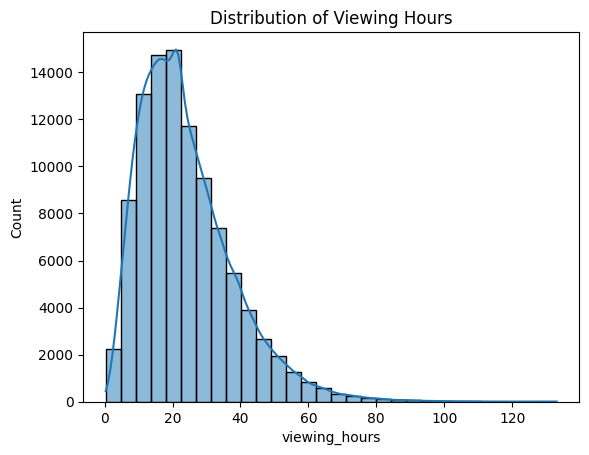

In [71]:
sns.histplot(data=df, x="viewing_hours", bins=30, kde=True)
plt.title("Distribution of Viewing Hours")
plt.show()

In [72]:
df.to_excel("Netflix Project.xlsx")

In [73]:
from google.colab import files
files.download("Netflix Project.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>